# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2 (Trang 15-17) - Câu 4: Khảo sát mối liên hệ giữa Cổng lên tàu (embarked) và Loại vé (pclass) với Khả năng sống sót (survived), phân biệt theo Giới tính (sex)

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


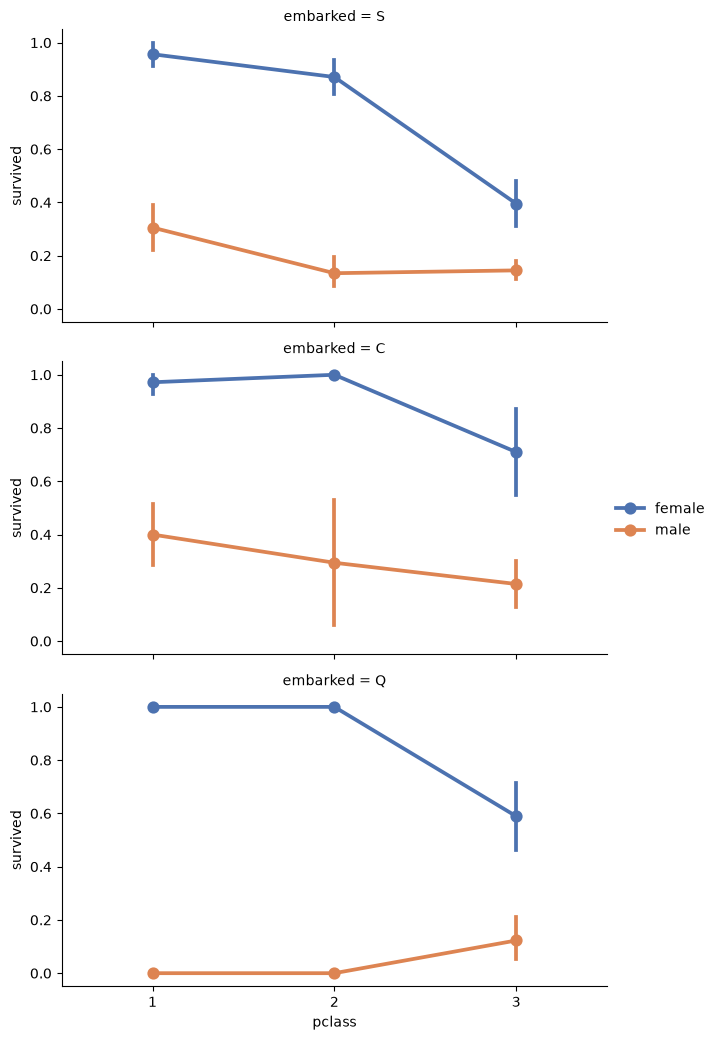

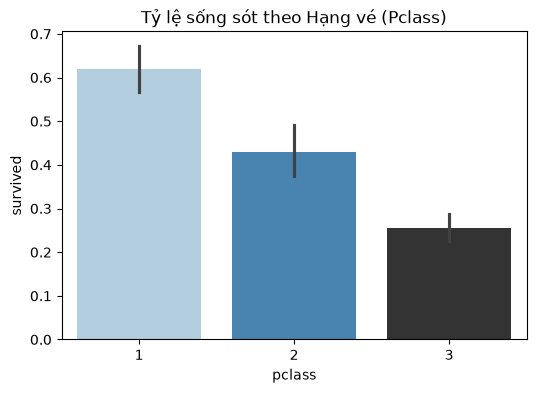

In [1]:
# Nguyễn Thành Trí - 6451071079
# Bài 2 (15-17) - Câu 4: Khảo sát Cổng lên tàu (embarked) và Loại vé (pclass) với Survived

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

# Đọc dữ liệu
def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join('..', rel_path),
        os.path.join('..', '..', rel_path),
        os.path.join('datasets', os.path.basename(rel_path)),
        os.path.join('..', 'datasets', os.path.basename(rel_path)),
        os.path.join('..', '..', 'datasets', os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f'Không tìm thấy file dữ liệu: {rel_path}')

csv_path = get_data_path('titanic.csv')
df = pd.read_csv(csv_path, na_values=['?'])
df.columns = df.columns.str.lower()
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df['fare'] = pd.to_numeric(df['fare'], errors='coerce')

# Vẽ biểu đồ FacetGrid pointplot theo 3 cổng lên tàu S, C, Q
FacetGrid = sns.FacetGrid(df, row='embarked', height=3.5, aspect=1.8)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()

def get_img_dir(subpath=''):
    for base in ['.', '..', '../..']:
        img_root = os.path.join(base, 'images')
        if os.path.exists(img_root) and (os.path.exists(os.path.join(base, 'datasets')) or os.path.exists(os.path.join(base, 'CLAUDE.md'))):
            target = os.path.join(img_root, subpath) if subpath else img_root
            os.makedirs(target, exist_ok=True)
            return target
    target = os.path.join('images', subpath) if subpath else 'images'
    os.makedirs(target, exist_ok=True)
    return target

img_dir = get_img_dir('Phan1/Bai1')
plt.savefig(os.path.join(img_dir, 'titanic_embarked_pclass_survived.png'), dpi=300, bbox_inches='tight')
plt.show()

# Biểu đồ phụ trợ: Tỷ lệ sống sót theo hạng vé (pclass)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df, ax=ax, palette='Blues_d', hue='pclass', legend=False)
ax.set_title("Tỷ lệ sống sót theo Hạng vé (Pclass)")
plt.savefig(os.path.join(img_dir, 'titanic_pclass_survived.png'), dpi=300, bbox_inches='tight')
